In [6]:
import torch

x = torch.rand(1, 3, 3, 3)
print(x)
print("=-------===========================")
x = x.view(1, 1, 3, 1, 3, 3)
print(x)

tensor([[[[0.0446, 0.1155, 0.1278],
          [0.9513, 0.6427, 0.1480],
          [0.7290, 0.5838, 0.4831]],

         [[0.7694, 0.9194, 0.2707],
          [0.2752, 0.6479, 0.8613],
          [0.0449, 0.8077, 0.1231]],

         [[0.2476, 0.4180, 0.7253],
          [0.0638, 0.3406, 0.8899],
          [0.6734, 0.8323, 0.6908]]]])
=-------===========================
tensor([[[[[[0.0446, 0.1155, 0.1278],
            [0.9513, 0.6427, 0.1480],
            [0.7290, 0.5838, 0.4831]]],


          [[[0.7694, 0.9194, 0.2707],
            [0.2752, 0.6479, 0.8613],
            [0.0449, 0.8077, 0.1231]]],


          [[[0.2476, 0.4180, 0.7253],
            [0.0638, 0.3406, 0.8899],
            [0.6734, 0.8323, 0.6908]]]]]])


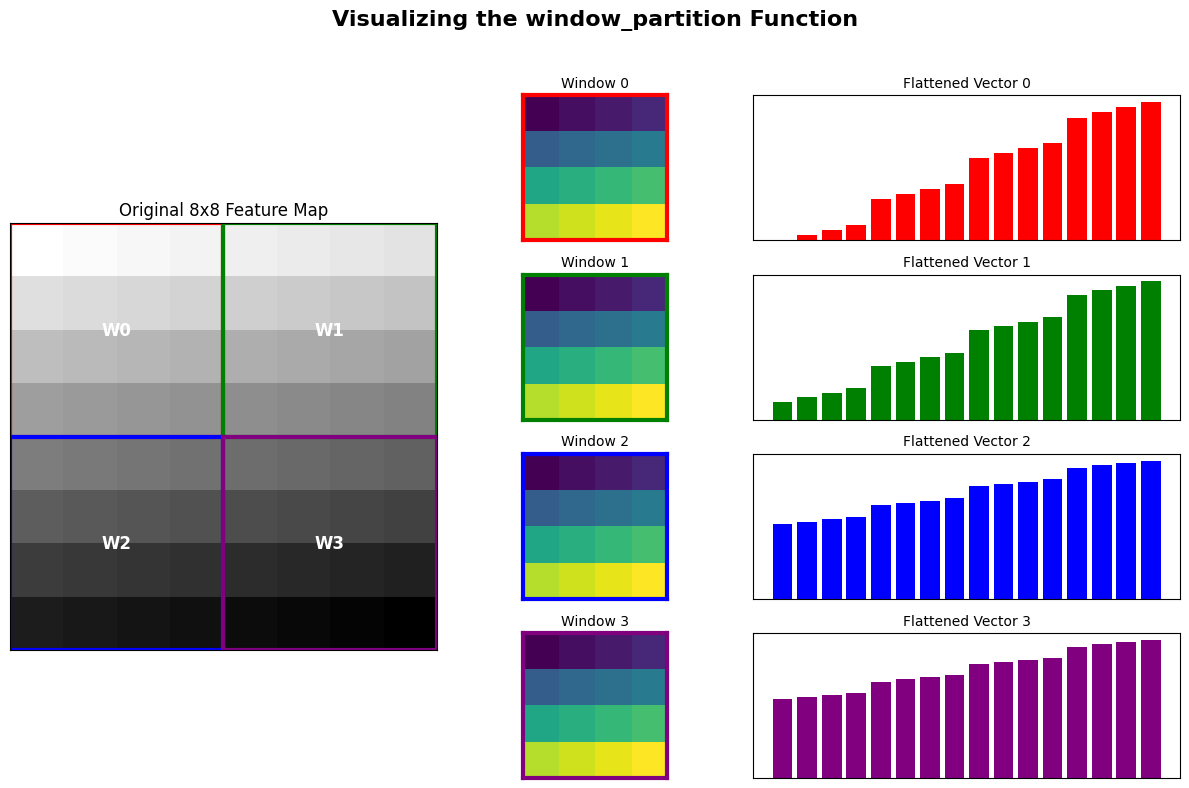

In [8]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

def window_partition(x, window_size):
    B, H, W, C = x.shape
    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)
    windows = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size**2, C)
    return windows

# 1. Create a sample input feature map
H, W = 8, 8
window_size = 4
feature_map = torch.arange(H * W).reshape(1, H, W, 1)

# 2. Apply the window partition function
partitioned_windows = window_partition(feature_map, window_size)
num_windows = partitioned_windows.shape[0]

# --- Enhanced Visualization ---
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(num_windows, 3) # GridSpec for layout

# --- Panel 1: Original Image with Colored Window Overlays ---
ax_orig = fig.add_subplot(gs[:, 0])
ax_orig.matshow(feature_map.squeeze().numpy(), cmap='gray_r')
ax_orig.set_title(f'Original {H}x{W} Feature Map')
ax_orig.set_xticks([])
ax_orig.set_yticks([])

colors = ['red', 'green', 'blue', 'purple']
window_coords = []
for i in range(H // window_size):
    for j in range(W // window_size):
        window_coords.append((j * window_size, i * window_size))

for i, (x, y) in enumerate(window_coords):
    rect = Rectangle((x - 0.5, y - 0.5), window_size, window_size,
                     linewidth=3, edgecolor=colors[i % len(colors)], facecolor='none')
    ax_orig.add_patch(rect)
    ax_orig.text(x + window_size/2 - 0.5, y + window_size/2 - 0.5, f'W{i}',
                 color='white', ha='center', va='center', fontsize=12, weight='bold')


# --- Panels 2 & 3: Extracted Windows and Flattened Vectors ---
for i in range(num_windows):
    # Extract the i-th window and reshape it back to 2D for plotting
    window_2d = partitioned_windows[i].reshape(window_size, window_size, -1).squeeze().numpy()
    
    # Panel 2: Show the individual window
    ax_win = fig.add_subplot(gs[i, 1])
    ax_win.matshow(window_2d, cmap='viridis')
    ax_win.set_title(f'Window {i}', fontsize=10)
    ax_win.set_xticks([])
    ax_win.set_yticks([])
    # Add colored border
    for spine in ax_win.spines.values():
        spine.set_edgecolor(colors[i % len(colors)])
        spine.set_linewidth(3)

    # Panel 3: Show the flattened vector representation
    ax_vec = fig.add_subplot(gs[i, 2])
    vector = partitioned_windows[i].squeeze().numpy()
    ax_vec.bar(np.arange(len(vector)), vector, color=colors[i % len(colors)])
    ax_vec.set_title(f'Flattened Vector {i}', fontsize=10)
    ax_vec.set_xticks([])
    ax_vec.set_yticks([])


fig.suptitle('Visualizing the window_partition Function', fontsize=16, weight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [13]:
x = torch.tensor([[1, 2, 3, 4], [5, 6, 7, 8],
                  [9, 10, 11, 12], [13, 14, 15, 16]])
x = x.view(2, 2, 2, 2)
print(x)

tensor([[[[ 1,  2],
          [ 3,  4]],

         [[ 5,  6],
          [ 7,  8]]],


        [[[ 9, 10],
          [11, 12]],

         [[13, 14],
          [15, 16]]]])


In [21]:
def window_partition(x, window_size):

    B, H, W, C = x.shape

    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)

    windows = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size**2, C)

    return windows

x = torch.arange(256).reshape(1,16,16,1)
# print(x)
# print("==============================")
window_p = window_partition(x, 4)
print(window_p)

tensor([[[  0],
         [  1],
         [  2],
         [  3],
         [ 16],
         [ 17],
         [ 18],
         [ 19],
         [ 32],
         [ 33],
         [ 34],
         [ 35],
         [ 48],
         [ 49],
         [ 50],
         [ 51]],

        [[  4],
         [  5],
         [  6],
         [  7],
         [ 20],
         [ 21],
         [ 22],
         [ 23],
         [ 36],
         [ 37],
         [ 38],
         [ 39],
         [ 52],
         [ 53],
         [ 54],
         [ 55]],

        [[  8],
         [  9],
         [ 10],
         [ 11],
         [ 24],
         [ 25],
         [ 26],
         [ 27],
         [ 40],
         [ 41],
         [ 42],
         [ 43],
         [ 56],
         [ 57],
         [ 58],
         [ 59]],

        [[ 12],
         [ 13],
         [ 14],
         [ 15],
         [ 28],
         [ 29],
         [ 30],
         [ 31],
         [ 44],
         [ 45],
         [ 46],
         [ 47],
         [ 60],
         [ 61],
  